# Willsey 2025 as a neuralset Study

`Willsey2025FingerDecoding` adapts the release into standardized events. One timeline is one task block, not one recording day: a day holds several blocks whose task dimensionality and online decoder differ, and a timeline needs invariant task entities.

Each timeline emits two or three whole-block continuous streams plus two rows per trial. The open-loop blocks have no decoder, so they carry the cued posture without a decoded one, which is the emission path this notebook checks alongside the closed-loop one.

Every stream starts at the first full 50 ms bin rather than at bin 0. A block opens with 76 to 88 bins that are 20 ms wide, and treating those as part of a uniform 20 Hz signal would misplace roughly 1.6 s of data. No trial starts before bin 192, so nothing is lost.

In [1]:
import matplotlib.pyplot as plt
import neuralset as ns
import numpy as np
import pandas as pd

from neuralshed.datasets.utils import dataset_dir
from neuralshed.datasets.willsey_2025 import utils
from neuralshed.datasets.willsey_2025.study import Willsey2025FingerDecoding
from neuralshed.extractors import BehavioralSeriesExtractor, NeuralFeatureExtractor

## Building the Study

The query picks three timelines that between them cover every emission path: an open-loop block, a closed-loop block whose task cued two degrees of freedom while a four-dimensional decoder ran, and a fully labelled four-dimensional block. This is the same query the Study's `_info` guard records.

In [2]:
study = Willsey2025FingerDecoding(
    path=str(dataset_dir("willsey_2025") / "data"),
    query="timeline_index in [25, 30, 53]",
)
study.download()

2026-09-04 15:41:46 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/willsey_2025/data/Willsey2025FingerDecoding.
2026-09-04 15:41:46 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/willsey_2025/data/Willsey2025FingerDecoding (skipped 0 non-owned items).


In [3]:
events = study.run()

print(f"timelines in the full study: {study._info.num_timelines}")
print(f"events in this query: {len(events)} across {events.timeline.nunique()} timelines")
print(f"subject: {events.subject.unique()}")

timelines in the full study: 60
events in this query: 404 across 3 timelines
subject: ['Willsey2025FingerDecoding/T5']


## The standardized events table

`type`, `start` and `duration` are the required columns. Everything else rides along, either broadcast from the timeline dict (the block's task, dimensionality and date) or attached per row.

In [4]:
print(events.type.value_counts().to_string())
print()
print("columns:", sorted(events.columns))

type
Stimulus             198
Action               198
BandPower              3
TargetGraspSeries      3
GraspSeries            2

columns: ['action_kind', 'block', 'block_kind', 'brain_region', 'code', 'condition', 'dataset_id', 'date', 'decoder_dof', 'description', 'dims', 'duration', 'feature', 'filepath', 'frequency', 'kind', 'lower_freq', 'modality', 'n_features', 'new_targets', 'normalization', 'participant_id', 'post_implant_day', 'processing', 'reference_frame', 'relative_path', 'run', 'session', 'start', 'start_time', 'stimulus_kind', 'stop', 'study', 'subject', 'target_index_middle', 'target_ring_little', 'target_thumb_abduction', 'target_thumb_flexion', 'task', 'task_condition', 'task_dof', 'timeline', 'trial_id', 'type', 'unit', 'upper_freq']


In [5]:
columns = ["type", "start", "duration", "task", "code", "condition", "trial_id", "feature"]
one = events[events.timeline == events.timeline.iloc[0]]
one[columns].head(8)

,type,start,duration,task,code,condition,trial_id,feature
0,BandPower,0.00,315.1,cuedmovement,NaN,NaN,NaN,spike_band_power
1,TargetGraspSeries,0.00,315.1,cuedmovement,NaN,NaN,NaN,finger_target
2,Stimulus,1.65,2.0,cuedmovement,2.0,thumb_flexion-extend,0.0,NaN
3,Action,1.65,2.0,cuedmovement,2.0,thumb_flexion-extend,0.0,NaN
4,Stimulus,4.65,2.0,cuedmovement,0.0,rest,1.0,NaN
5,Action,4.65,2.0,cuedmovement,0.0,rest,1.0,NaN
6,Stimulus,7.65,2.0,cuedmovement,0.0,rest,2.0,NaN
7,Action,7.65,2.0,cuedmovement,0.0,rest,2.0,NaN


## Timeline-level attributes

Every key in the timeline dict is broadcast to all of that block's rows, which is what makes them usable as filters at training time. `task_dof` is read off the target stream, `decoder_dof` and `new_targets` come from the authors' notebook because the files do not record them, and `post_implant_day` is what any drift analysis needs.

The framework broadcasts these as strings, so the Study emits them as strings with `""` for not-applicable rather than as integers that would arrive as the literal `"None"`. Filters compare against `"4"`, not `4`.

In [6]:
attributes = [
    "session",
    "run",
    "task",
    "block_kind",
    "task_dof",
    "decoder_dof",
    "new_targets",
    "date",
    "post_implant_day",
]
events.groupby("timeline")[attributes].first()

,session,run,task,block_kind,task_dof,decoder_dof,new_targets,date,post_implant_day
timeline,,,,,,,,,
"Willsey2025FingerDecoding:block=31,block_kind=closed_loop,date=2023-04-06,decoder_dof=4,new_targets=,post_implant_day=2423,relative_path=20230406/RedisMat/t5_t5.2023.04.06_Data_RedisMat_20230406_160214_(31).mat,run=block31,session=t5.2023.04.06,start_time=160214,subject=T5,task=fingertargets,task_dof=2",t5.2023.04.06,block31,fingertargets,closed_loop,2,4,,2023-04-06,2423
"Willsey2025FingerDecoding:block=44,block_kind=closed_loop,date=2023-04-13,decoder_dof=4,new_targets=1,post_implant_day=2430,relative_path=20230413/RedisMat/t5_t5.2023.04.13_Data_RedisMat_20230413_153016_(44).mat,run=block44,session=t5.2023.04.13,start_time=153016,subject=T5,task=fingertargets,task_dof=4",t5.2023.04.13,block44,fingertargets,closed_loop,4,4,1,2023-04-13,2430
"Willsey2025FingerDecoding:block=5,block_kind=open_loop,date=2023-04-06,decoder_dof=,new_targets=,post_implant_day=2423,relative_path=OpenLoopData/t5_t5.2023.04.06_Data_RedisMat_20230406_134920_(5).mat,run=block05,session=t5.2023.04.06,start_time=134920,subject=T5,task=cuedmovement,task_dof=",t5.2023.04.06,block05,cuedmovement,open_loop,,,,2023-04-06,2423


The open-loop block carries no `GraspSeries`, since nothing decoded a posture there, so the emitted stream set is not identical across timelines.

In [7]:
pd.crosstab(events.timeline, events.type)

type,Action,BandPower,GraspSeries,Stimulus,TargetGraspSeries
timeline,,,,,
"Willsey2025FingerDecoding:block=31,block_kind=closed_loop,date=2023-04-06,decoder_dof=4,new_targets=,post_implant_day=2423,relative_path=20230406/RedisMat/t5_t5.2023.04.06_Data_RedisMat_20230406_160214_(31).mat,run=block31,session=t5.2023.04.06,start_time=160214,subject=T5,task=fingertargets,task_dof=2",49,1,1,49,1
"Willsey2025FingerDecoding:block=44,block_kind=closed_loop,date=2023-04-13,decoder_dof=4,new_targets=1,post_implant_day=2430,relative_path=20230413/RedisMat/t5_t5.2023.04.13_Data_RedisMat_20230413_153016_(44).mat,run=block44,session=t5.2023.04.13,start_time=153016,subject=T5,task=fingertargets,task_dof=4",49,1,1,49,1
"Willsey2025FingerDecoding:block=5,block_kind=open_loop,date=2023-04-06,decoder_dof=,new_targets=,post_implant_day=2423,relative_path=OpenLoopData/t5_t5.2023.04.06_Data_RedisMat_20230406_134920_(5).mat,run=block05,session=t5.2023.04.06,start_time=134920,subject=T5,task=cuedmovement,task_dof=",100,1,0,100,1


## Reading the continuous streams

The streams are read through their extractors. Everything is dims-first `(n_rows, T)` and shares the block's 20 Hz time base, so the neural and behavioral arrays line up sample for sample.

The neural stream asks for `target_unit="native"`. Spike-band power is declared `uV^2`, summed over the bin rather than averaged, so it is extensive. `units.py` registers `uV^2` as non-convertible, so the extractor applies no bin-width factor to it either way and `"native"` costs nothing here.

In [8]:
segmenter = ns.dataloader.Segmenter(
    extractors={
        "neural": NeuralFeatureExtractor(
            target_unit="native", frequency=20, event_types="BandPower"
        ),
        "posture": BehavioralSeriesExtractor(frequency=20, event_types="GraspSeries"),
        "target": BehavioralSeriesExtractor(frequency=20, event_types="TargetGraspSeries"),
    },
    trigger_query="type == 'Action' and action_kind == 'finger_control'",
    duration=None,
)
closed_loop = events[events.block_kind == "closed_loop"]
segments = segmenter.apply(closed_loop)
segments.prepare()
segments.pad_duration = "auto"

print(f"one segment per trial: {len(segments)}")
print({key: tuple(value.shape) for key, value in segments[0].data.items()})

2026-09-04 15:41:59 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00, 1415.56it/s]
2026-09-04 15:41:59 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00, 459.57it/s]
2026-09-04 15:41:59 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00, 373.54it/s]

one segment per trial: 98
{'neural': (1, 192, 102), 'posture': (1, 4, 102), 'target': (1, 4, 102)}


`GraspSeries` and `TargetGraspSeries` are separate types carrying the same four dimensions, so a decoder can read the cue and the outcome as two streams of the same shape. Selection is by type name, which is why the target needed its own type rather than an attribute on one shared stream.

In [9]:
print("dimensions:", utils.DECODED_DIMS)
row = events[events.type == "GraspSeries"].iloc[0]
print(f"dims on the event row: {row['dims']}")
print(f"unit: {row['unit']!r}  (0 = fully flexed, 1 = fully extended)")
neural_row = events[events.type == "BandPower"].iloc[0]
print(f"neural unit: {neural_row['unit']!r}  normalization: {neural_row['normalization']!r}")
print(f"processing: {neural_row['processing']!r}")

dimensions: ('thumb_flexion', 'thumb_abduction', 'index_middle', 'ring_little')
dims on the event row: ('thumb_flexion', 'thumb_abduction', 'index_middle', 'ring_little')
unit: 'proportion'  (0 = fully flexed, 1 = fully extended)
neural unit: 'uV^2'  normalization: 'raw'
processing: '250 Hz digital high-pass; common average referencing; sum of squared magnitude per 50 ms bin'


The open-loop block emits only the neural stream and the cued posture, so it needs its own extractor set. Its trials are the 2 s go phases and their `condition` names one of the nine cued postures.

In [10]:
open_loop = events[events.block_kind == "open_loop"]

open_segmenter = ns.dataloader.Segmenter(
    extractors={
        "neural": NeuralFeatureExtractor(
            target_unit="native", frequency=20, event_types="BandPower"
        ),
        "target": BehavioralSeriesExtractor(frequency=20, event_types="TargetGraspSeries"),
    },
    trigger_query="type == 'Action'",
    duration=None,
)
open_segments = open_segmenter.apply(open_loop)
open_segments.prepare()
open_segments.pad_duration = "auto"

print(f"go phases: {len(open_segments)}")
print({key: tuple(value.shape) for key, value in open_segments[0].data.items()})
print()
print(open_loop[open_loop.type == "Action"].groupby("condition").size().to_string())

2026-09-04 15:42:00 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor
2026-09-04 15:42:00 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


go phases: 100
{'neural': (1, 192, 40), 'target': (1, 4, 40)}

condition
index_middle-extend        5
index_middle-flex          6
rest                      56
ring_little-extend         5
ring_little-flex           6
thumb_abduction-extend     6
thumb_abduction-flex       5
thumb_flexion-extend       5
thumb_flexion-flex         6


## Checking the streams against each other

A useful sanity check on the alignment: within a trial the hand should travel towards its target, so the distance from posture to target should fall. Reading a whole block's streams and overlaying the trial boundaries shows the task structure directly.

In [11]:
block_segmenter = ns.dataloader.Segmenter(
    extractors={
        "neural": NeuralFeatureExtractor(
            target_unit="native", frequency=20, event_types="BandPower"
        ),
        "posture": BehavioralSeriesExtractor(frequency=20, event_types="GraspSeries"),
        "target": BehavioralSeriesExtractor(frequency=20, event_types="TargetGraspSeries"),
    },
    trigger_query="type == 'BandPower'",
    duration=None,
)
four_dof = events[(events.block_kind == "closed_loop") & (events.task_dof == "4")]
timeline = four_dof.timeline.iloc[0]
whole = block_segmenter.apply(four_dof[four_dof.timeline == timeline])
whole.prepare()
whole.pad_duration = "auto"
block = whole[0].data

neural = np.asarray(block["neural"])[0]
posture = np.asarray(block["posture"])[0]
target = np.asarray(block["target"])[0]
print(f"timeline: {four_dof.session.iloc[0]}_{four_dof.run.iloc[0]}")
print(f"neural {neural.shape}  posture {posture.shape}  target {target.shape}")

2026-09-04 15:42:00 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor
2026-09-04 15:42:00 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor
2026-09-04 15:42:00 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


timeline: t5.2023.04.13_block44
neural (192, 2046)  posture (4, 2046)  target (4, 2046)


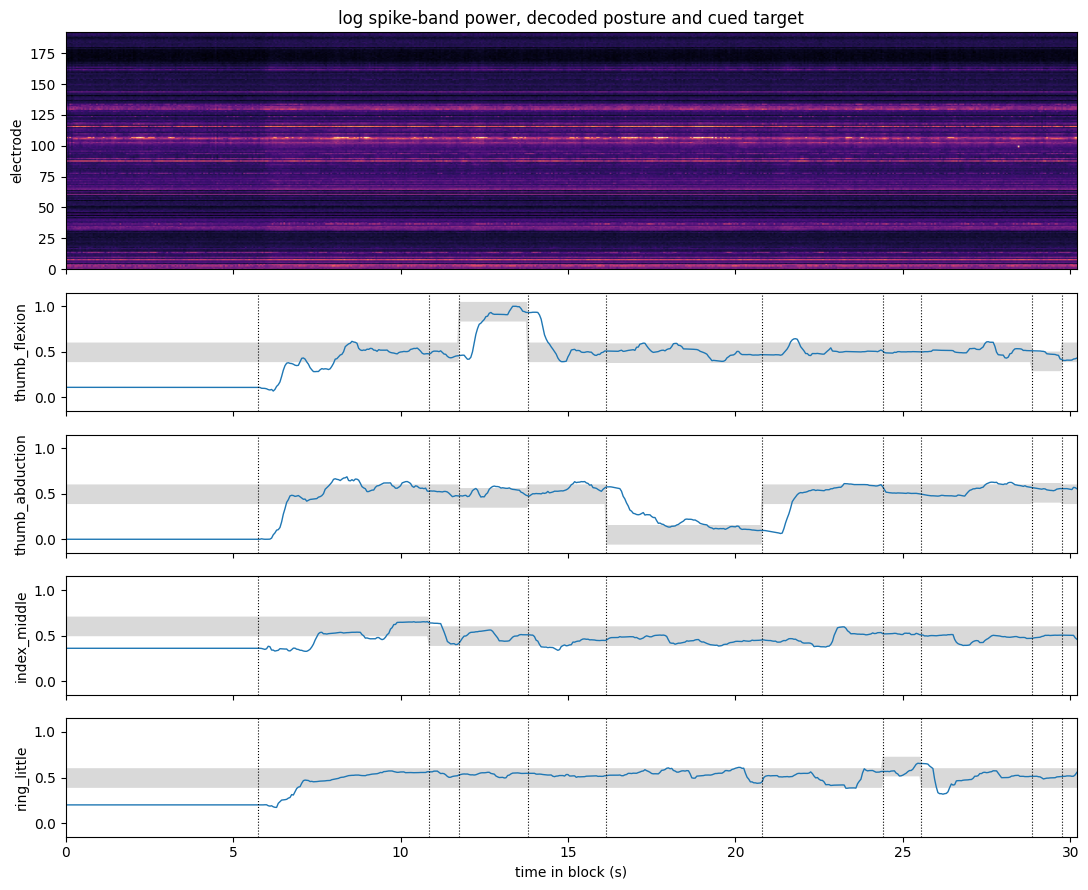

In [12]:
trials = four_dof[(four_dof.timeline == timeline) & (four_dof.type == "Action")].head(10)
window = slice(0, int(trials.iloc[-1].stop * utils.FS))
time = np.arange(neural.shape[1])[window] / utils.FS

fig, axes = plt.subplots(5, 1, figsize=(11, 9), sharex=True, height_ratios=[2, 1, 1, 1, 1])
axes[0].imshow(
    np.log1p(neural[:, window]),
    aspect="auto",
    origin="lower",
    extent=[time[0], time[-1], 0, neural.shape[0]],
    cmap="magma",
)
axes[0].set(ylabel="electrode", title="log spike-band power, decoded posture and cued target")

for k, dim in enumerate(utils.DECODED_DIMS):
    ax = axes[k + 1]
    ax.fill_between(
        time,
        target[k, window] - utils.TARGET_HALF_WIDTH,
        target[k, window] + utils.TARGET_HALF_WIDTH,
        color="0.85",
    )
    ax.plot(time, posture[k, window], color="C0", lw=1)
    ax.set(ylabel=dim, ylim=(-0.15, 1.15))
for _, trial in trials.iterrows():
    for ax in axes[1:]:
        ax.axvline(trial.start, color="k", ls=":", lw=0.8)
axes[-1].set_xlabel("time in block (s)")
plt.tight_layout()

Each dotted line is a new target. The posture entering and staying inside the grey band confirms the trial rows are aligned to the behavioral streams. Quantifying the same thing across every trial in the query is a stronger check than one plot.

In [13]:
starts, ends = [], []
for segment in segments:
    # Segments are padded to the longest trial, so slice back to this trial's own bins
    # before reading the first and last sample.
    n = int(round(float(segment.triggers.iloc[0]["duration"]) * utils.FS))
    pos = np.asarray(segment.data["posture"])[0][:, :n]
    tgt = np.asarray(segment.data["target"])[0][:, :n]
    distance = np.linalg.norm(tgt - pos, axis=0)
    if n > 4:
        starts.append(distance[0])
        ends.append(distance[-1])

starts, ends = np.array(starts), np.array(ends)
print(f"trials checked: {len(starts)}")
print(f"median distance at trial start: {np.median(starts):.3f}")
print(f"median distance at trial end:   {np.median(ends):.3f}")
print(f"trials ending closer than they started: {(ends < starts).mean():.1%}")
print(f"trials ending inside the target tolerance: {(ends < 2 * utils.TARGET_HALF_WIDTH).mean():.1%}")

trials checked: 98
median distance at trial start: 0.377
median distance at trial end:   0.065
trials ending closer than they started: 98.0%
trials ending inside the target tolerance: 100.0%


## Filtering by attribute

Selection is by type name in extractors, so anything else has to be an attribute. The columns the Study emits are chosen so the slices a model might want are all reachable: hold out whole sessions by `session` or `post_implant_day`, split the two task dimensionalities by `task_dof`, isolate the decoder comparison by `decoder_dof`, drop the return-to-neutral half of the trials by `condition`, or train on one cued movement at a time in the open-loop blocks.

In [14]:
actions = events[events.type == "Action"]

print("trials per block kind and task dimensionality:")
print(actions.groupby(["block_kind", "task_dof"]).size().to_string())
print()
print("closed-loop trials per condition:")
print(actions[actions.block_kind == "closed_loop"].groupby("condition").size().to_string())

reaching = events.query("type == 'Action' and condition == 'random_target'")
print(f"\ntrials that cue a new posture rather than a return to neutral: {len(reaching)}")

control = events.query("type == 'Action' and task_dof == '2' and decoder_dof == '4'")
print(f"trials in the four-dimensional-decoder-on-two-dimensional-task control: {len(control)}")

trials per block kind and task dimensionality:
block_kind   task_dof
closed_loop  2            49
             4            49
open_loop                100

closed-loop trials per condition:
condition
random_target        50
return_to_neutral    48

trials that cue a new posture rather than a return to neutral: 50
trials in the four-dimensional-decoder-on-two-dimensional-task control: 49


## Summary

- 60 timelines, one per recorded block, with the quadcopter flight path excluded because it has no neural data.
- Closed-loop blocks emit `BandPower`, `GraspSeries` and `TargetGraspSeries`; open-loop blocks emit the first and last, since nothing decoded a posture there.
- Two rows per trial, a visual `Stimulus` for the cue and an attempted `Action` for the movement, sharing a `condition` and a `code` that mean the same thing across both block kinds.
- Streams start at the first full 50 ms bin, so a uniform 20 Hz time base holds for every array a segment returns.
- The filters that matter are on the events table: `task_dof` and `decoder_dof` per block, `condition` per trial, `session` and `post_implant_day` for held-out splits.